# 2 Ising model

## Critical phenomena

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
    
**Note:** This notebook contains the code for section 2.3-2.4 from the book
    
**Simulation of Complex Systems**
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)
    
    
You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

<a id="critical-temperature"></a>
### 2.3 Critical temperature

For the nearest-neighbor, zero-field 2D square-lattice Ising model, with $J>0$,

$$\frac{k_BT_c}{J}=\frac{2}{\ln(1+\sqrt2)}\approx 2.269185.$$

This is the **infinite-lattice** result. Finite lattices have rounded transitions and correlated magnetization fluctuations. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.insert(0, "../02_modules")
import ising_model as im

rng = np.random.default_rng()

Tc = 2 / np.log(1 + np.sqrt(2))
print(f"Exact infinite-system critical temperature: {Tc:.6f} J/k_B")

Exact infinite-system critical temperature: 2.269185 J/k_B


<a id="critical-T"></a>
Let's examine now the magnetization for different temperatures.

In [2]:
T_values = [1.0, 1.5, 2.0, Tc, 2.3, 2.4, 2.5, 3.0, 4.0, 5.0]
m_av = []  # magnetization (mean value)
m_sig = []  # magnetization (standard deviation)

repetitions = 10  # we need independent runs

N = 48  # lattice side
H_ini = 0.1  # for initial equilibration (needed when for T<Tc) 
H = 0.0
J = 1.0
kB = 1.0
f = 0.1
n_ini = 1000  # for initial equilibration
n_steps = 2000  # for the average at equilibrium

rng = np.random.default_rng()

for T in T_values:
    m = [];
    for _ in range(repetitions):
        spins = im.random_spins(N, rng)
        # initially use H_ini (>0)
        im.simulate(spins, T, n_ini, rng, J, H_ini, kB, f, n_ini)
        # then use H = 0
        im.simulate(spins, T, n_ini, rng, J, H, kB, f, n_ini)
        # initial equilibration done
        im.simulate(spins, T, n_steps, rng, J, H, kB, f, n_steps)
        m.append(im.magnetization(spins))        
    m_av.append(np.mean(m))
    m_sig.append(np.std(m))
    

Let's plot the magnetization as a function of the temperature.

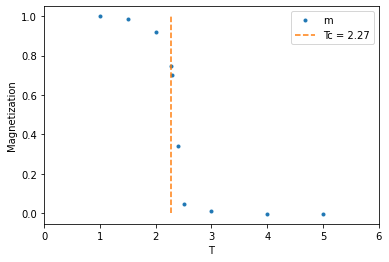

In [3]:
# plt.errorbar(T_values, m_av, yerr=m_sig, fmt="o-", capsize=3)
plt.plot(T_values, m_av, ".", label="m")
plt.plot([Tc, Tc], [0, 1], "--", label=f"Tc = {Tc:.2f}")
plt.xlabel("T")
plt.ylabel("Magnetization")
plt.xlim([0.0, 6.0])
plt.legend()
plt.show()

What happens to the magnetization around $T_c$?

<a id="critical-mixtures"></a>
### 2.4 Critical mixtures

A binary mixture can be represented schematically by two spin values, corresponding to local preference for component A or B. Above an upper critical solution temperature the mixture is homogeneous on large scales; close to criticality the composition fluctuations become correlated over longer distances (textbook §2.4).

Critical parameter: $\xi$ (correlation length of critical fluctuations)

$$\xi\propto \left(\frac{T_c -T}{T_c}\right)^{-\nu}$$

with $\nu=0.63$ (Eq. 2.4). 

<a id="plates"></a>
Critical Casimir effect: illustrated here with two parallel plates.

*(Note that it's slightly different from the book.)*

Plates' separation: 10


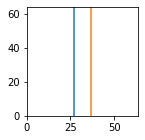

In [4]:
N = 64
L = 5
x1 = N // 2 - L
x2 = N // 2 + L

D = x2 - x1

print("Plates' separation:", D)

plt.figure(figsize=(2,2))
plt.plot([x1, x1], [0, N], '-')
plt.plot([x2, x2], [0, N], '-')
plt.xlim([0, N])
plt.ylim([0, N])
plt.show()

The plates do not move. 

Depending on their adsorpion properties (hydrophilic, hydrophobic), they prefer one or the other component of the critical mixture.

Here, we mimic the effect by imposing a certain orientation of the spins.

In [5]:
temperatures = [1.0, 2.269, 5.0]  # we test three different T

Nx = 64
Ny = 32
L = 10

kB = 1.0
H = 0.0
J = 1.0
f = 0.1

x1 = Nx // 2 - L
x2 = Nx // 2 + L
D = x2 - x1

s1 = 1  # spins at plate 1
s2 = 1  # spins at plate 2

n_steps = 500

rng = np.random.default_rng()

snapshots_start = []
snapshots_end = []
for T in temperatures:
    spins = im.spins_plates_rectangular(Nx, Ny, x1, x2, s1, s2, rng)
    snapshots_start.append(spins.copy())
    m = im.simulate_plates(
        spins, x1, x2, s1, s2, T, n_steps, rng, J, H, kB, f, n_steps)
    snapshots_end.append(spins.copy())

Let's plot initial and final snapshot

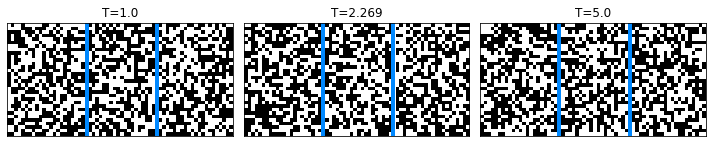

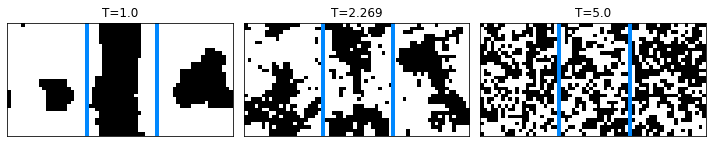

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, temperature, lattice in zip(axes, temperatures, 
                                    snapshots_start):
    ax.imshow(
        lattice, 
        cmap="gray", 
        vmin=-1, 
        vmax=1, 
        interpolation="nearest"
    )
    ax.axvline(x=x1, color="#0088FF", linestyle="-", linewidth=4)
    ax.axvline(x=x2, color="#0088FF", linestyle="-", linewidth=4)
    ax.set(title=f"T={temperature}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, temperature, lattice in zip(axes, temperatures, 
                                    snapshots_end):
    ax.imshow(
        lattice, 
        cmap="gray", 
        vmin=-1, 
        vmax=1, 
        interpolation="nearest"
    )
    ax.axvline(x=x1, color="#0088FF", linestyle="-", linewidth=4)
    ax.axvline(x=x2, color="#0088FF", linestyle="-", linewidth=4)
    ax.set(title=f"T={temperature}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

<a id="questions"></a>

## Questions

Here you find the questions:

- [Q10: Critical temperature](#q10)
- [Q11: Critical Casimir effect](#q11)

<a id="q10"></a>

**Question 10:** Critical temperature and phase transition.

Refer to [Critical temperature](#critical-temperature)

[Go back to questions](#questions)

Refer to the lines of code:
```python
m = [];
for _ in range(repetitions):
    spins = im.random_spins(N, rng)
    im.simulate(spins, T, n_ini, rng, J, H_ini, kB, f, n_ini)
    im.simulate(spins, T, n_ini, rng, J, H, kB, f, n_ini)    
    im.simulate(spins, T, n_steps, rng, J, H, kB, f, n_steps)
    m.append(im.magnetization(spins))        
```

a. Explain the logic behind simulating first `n_ini` steps with `H_ini` (>0), then simulating `n_ini` steps with `H` (=0), then simulating again `n_steps` (possibly $\ge$ n_ini) steps, and only after that measuring the magnetization `m`.


b. What could happen (for $T<T_c$) if we omit the step: 
```python
im.simulate(spins, T, n_ini, rng, J, H_ini, kB, f, n_ini)
```

c. Can we safely omit the step:
```python
im.simulate(spins, T, n_ini, rng, J, H_ini, kB, f, n_ini)
```
if  $T \ge T_c$? Why or why not?


d. Can you explain the phase transition in the graph $m(T)$ ?

<a id="q11"></a>

**Question 11:** Critical Casimir effect -- parallel plates.

Refer to [Critical Casimir effect](#plates)

[Go back to questions](#questions)

Here, the geometry of the lattice is `Nx = 64`, `Ny = 32`. $T < T_c$. The distance between the plates is $D = 20$. We let the system evolve long enough to get at the equilibrium.

a. We have two plates $(+,+)$. What is the aspect of the spins between the plates?

b. We have two plates $(-,-)$. What is the aspect of the spins between the plates?

c. We have two plates $(+,-)$. What is the aspect of the spins between the plates?


<br> Here, same geometry as before. Same distance. $T \ge T_c$

d. We have two plates $(+,+)$. What is the aspect of the spins between the plates?

e. We have two plates $(-,-)$. What is the aspect of the spins between the plates?

f. We have two plates $(+,-)$. What is the aspect of the spins between the plates?


<br> Here, same geometry as before. Same distance. 
Now $T = 2.26 \approx T_c$.

g. What is the aspect of the spins between the plates, when the plates are (+,-)?


<br> Experiment with a lattice with $Nx = 128$. $T = 2.26 \approx T_c$.


h. The plates are at a distance of D=32. What is the aspect of the spins between the plates, when the plates are (+,-)?


i. The plates are at a distance of D=10. What is the aspect of the spins between the plates, when the plates are (+,-)?
